In [22]:
import sqlite3
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import ceil
%config InlineBackend.figure_format = 'retina'
sns.set_theme()

In [23]:
import pandas as pd

caminho = r"C:\Users\35191\Downloads\acdc_dataset.csv"

# O python engine deteta automaticamente se é vírgula, ponto e vírgula, tab, etc.
df = pd.read_csv(caminho, sep=None, engine='python')
df.head()

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
0,CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,...,False,True,0,False,True,True,False,False,2,4477.97
1,CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,...,False,False,0,True,False,False,False,False,0,165.86
2,CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,...,False,False,0,False,False,False,False,False,1,4486.17
3,CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,...,False,False,0,False,False,False,False,False,0,258.63
4,CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,...,False,False,0,False,False,True,False,False,0,335.74


In [24]:
df.shape

(15465, 31)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   member_id                    15465 non-null  object 
 1   age                          14907 non-null  float64
 2   gender                       14935 non-null  object 
 3   industry                     15465 non-null  object 
 4   country                      15035 non-null  object 
 5   is_team_account              15465 non-null  bool   
 6   n_colleagues_on_account      15465 non-null  int64  
 7   plan_tier                    15360 non-null  object 
 8   plan_days_per_week           15465 non-null  int64  
 9   membership_start             15465 non-null  object 
 10  membership_end               15465 non-null  object 
 11  last_badge_swipe             15465 non-null  object 
 12  days_since_last_visit        15465 non-null  int64  
 13  total_visits    

In [6]:
df.dtypes

member_id                       object
age                            float64
gender                          object
industry                        object
country                         object
is_team_account                   bool
n_colleagues_on_account          int64
plan_tier                       object
plan_days_per_week               int64
membership_start                object
membership_end                  object
last_badge_swipe                object
days_since_last_visit            int64
total_visits                     int64
avg_weekly_visits              float64
entitled_visits_last_period    float64
actual_visits_last_period        int64
meeting_room_hours             float64
event_space_hours              float64
guest_passes_issued            float64
uses_meeting_rooms                bool
uses_event_space                  bool
uses_guest_passes                 bool
uses_print                       int64
uses_mail_handling                bool
uses_phone_booths        

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.858724,10.394649,1.0,29.00,34.00,40.00,149.00
n_colleagues_on_account,15465.0,0.537019,1.177668,-1.0,0.00,0.00,1.00,9.00
plan_days_per_week,15465.0,3.387262,1.458818,0.0,2.00,3.00,5.00,9.00
days_since_last_visit,15465.0,117.109279,275.532807,-956.0,4.00,13.00,55.00,1212.00
total_visits,15465.0,110.406531,182.939340,-112.0,8.00,34.00,132.00,6530.00
avg_weekly_visits,15465.0,1.777214,1.937515,0.0,0.71,1.42,2.41,47.40
entitled_visits_last_period,15465.0,27.517393,13.480235,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.800970,11.387207,0.0,5.00,10.00,20.00,60.00
meeting_room_hours,14167.0,33.075570,428.169678,-56.6,0.00,0.00,7.20,41220.00
event_space_hours,15465.0,5.117220,26.013097,-13.5,0.00,0.00,0.00,602.80


In [8]:
df.describe(include="O").T

,count,unique,top,freq
member_id,15465,15450,CW005845,2
gender,14935,12,Female,7414
industry,15465,43,Information Technology,3322
country,15035,33,Portugal,9959
plan_tier,15360,19,flex,5182
membership_start,15465,1539,2021-01-01,560
membership_end,15465,1423,1970-01-01,3956
last_badge_swipe,15465,1543,2023-12-30,279
lifetime_value,14425,11860,0,1725


In [9]:
df.head(10)

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
0,CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,...,False,True,0,False,True,True,False,False,2,4477.97
1,CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,...,False,False,0,True,False,False,False,False,0,165.86
2,CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,...,False,False,0,False,False,False,False,False,1,4486.17
3,CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,...,False,False,0,False,False,False,False,False,0,258.63
4,CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,...,False,False,0,False,False,True,False,False,0,335.74
5,CW000006,39.0,Male,Health,Portugal,False,0,flex,3,2021-05-31,...,False,False,1,True,False,False,False,False,0,413.17
6,CW000007,23.0,Female,Unknown,Portugal,True,2,hot_desk,2,2022-01-17,...,False,True,0,False,False,False,False,False,0,257.95
7,CW000008,33.0,Male,Information Technology,Portugal,True,3,flex,3,2021-03-28,...,False,False,0,False,False,False,True,False,0,4636.8
8,CW000009,30.0,Male,Other,Portugal,False,0,flex,3,2023-08-12,...,True,False,0,False,False,False,False,False,0,281.37
9,CW000010,44.0,Male,Consulting,Portugal,False,0,dedicated_desk,5,2022-06-06,...,False,True,1,True,True,False,True,False,1,8741.88


In [10]:
df.sum(numeric_only=True)

age                             519639.00
is_team_account                   4353.00
n_colleagues_on_account           8305.00
plan_days_per_week               52384.00
days_since_last_visit          1811095.00
total_visits                   1707437.00
avg_weekly_visits                27484.62
entitled_visits_last_period     425556.48
actual_visits_last_period       213432.00
meeting_room_hours              468581.60
event_space_hours                79137.80
guest_passes_issued              87477.00
uses_meeting_rooms                5263.00
uses_event_space                  1841.00
uses_guest_passes                 2814.00
uses_print                        4996.00
uses_mail_handling                3564.00
uses_phone_booths                 3996.00
uses_day_passes                   3396.00
uses_storage                      2296.00
uses_bike_locker                    26.00
n_renewals                       15550.00
dtype: float64

In [11]:
df.mean(numeric_only=True)

age                             34.858724
is_team_account                  0.281474
n_colleagues_on_account          0.537019
plan_days_per_week               3.387262
days_since_last_visit          117.109279
total_visits                   110.406531
avg_weekly_visits                1.777214
entitled_visits_last_period     27.517393
actual_visits_last_period       13.800970
meeting_room_hours              33.075570
event_space_hours                5.117220
guest_passes_issued              6.162956
uses_meeting_rooms               0.340317
uses_event_space                 0.119043
uses_guest_passes                0.181959
uses_print                       0.323052
uses_mail_handling               0.230456
uses_phone_booths                0.258390
uses_day_passes                  0.219593
uses_storage                     0.148464
uses_bike_locker                 0.001681
n_renewals                       1.005496
dtype: float64

In [12]:
df.isna().sum()

member_id                         0
age                             558
gender                          530
industry                          0
country                         430
is_team_account                   0
n_colleagues_on_account           0
plan_tier                       105
plan_days_per_week                0
membership_start                  0
membership_end                    0
last_badge_swipe                  0
days_since_last_visit             0
total_visits                      0
avg_weekly_visits                 0
entitled_visits_last_period       0
actual_visits_last_period         0
meeting_room_hours             1298
event_space_hours                 0
guest_passes_issued            1271
uses_meeting_rooms                0
uses_event_space                  0
uses_guest_passes                 0
uses_print                        0
uses_mail_handling                0
uses_phone_booths                 0
uses_day_passes                   0
uses_storage                

In [13]:
df["gender"].unique()

array(['Female', 'Male', 'F', 'Other', nan, ' Female', 'M', 'male',
       ' Male', 'other', ' Other', 'female', 'O'], dtype=object)

In [14]:
df["industry"].unique()

array(['Information Technology', 'Education', 'Legal', 'Health',
       'Unknown', 'Other', 'Consulting', 'Design & Creative',
       'information technology', 'Finance', 'Marketing & PR', 'EDUCATION',
       'DESIGN & CREATIVE', 'Marketing and PR', 'Real Estate', 'other',
       'consulting', 'MARKETING & PR', 'Information technology',
       'design & creative', 'LEGAL', 'marketing & pr',
       'INFORMATION TECHNOLOGY', 'health', 'Marketing/PR', 'CONSULTING',
       'unknown', 'Design/Creative', 'RealEstate', 'IT', 'Tech',
       'Marketing & Pr', 'OTHER', 'legal', 'finance', 'real estate',
       'education', 'Design and Creative', 'UNKNOWN', 'FINANCE',
       'REAL ESTATE', 'HEALTH', 'Real-Estate'], dtype=object)

In [15]:
df["plan_tier"].unique()

array(['flex', 'HOT_DESK', 'hot_desk', 'dedicated_desk', 'full_time',
       'private_office', 'Hot Desk', 'dedicateddesk', nan, 'FULL_TIME',
       'hotdesk', 'Flex', 'FLEX', 'fulltime', 'privateoffice',
       'Full Time', 'DEDICATED_DESK', 'Dedicated Desk', 'Private Office',
       'PRIVATE_OFFICE'], dtype=object)

In [16]:
df["membership_start"].unique()

array(['2021-08-01', '2023-11-24', '2021-12-03', ..., '10/10/2021',
       '18/05/2022', '08/10/2022'], shape=(1539,), dtype=object)

In [17]:
df.replace("", np.nan, inplace=True)
df.isna().sum()

member_id                         0
age                             558
gender                          530
industry                          0
country                         430
is_team_account                   0
n_colleagues_on_account           0
plan_tier                       105
plan_days_per_week                0
membership_start                  0
membership_end                    0
last_badge_swipe                  0
days_since_last_visit             0
total_visits                      0
avg_weekly_visits                 0
entitled_visits_last_period       0
actual_visits_last_period         0
meeting_room_hours             1298
event_space_hours                 0
guest_passes_issued            1271
uses_meeting_rooms                0
uses_event_space                  0
uses_guest_passes                 0
uses_print                        0
uses_mail_handling                0
uses_phone_booths                 0
uses_day_passes                   0
uses_storage                

In [18]:
df.dtypes

member_id                       object
age                            float64
gender                          object
industry                        object
country                         object
is_team_account                   bool
n_colleagues_on_account          int64
plan_tier                       object
plan_days_per_week               int64
membership_start                object
membership_end                  object
last_badge_swipe                object
days_since_last_visit            int64
total_visits                     int64
avg_weekly_visits              float64
entitled_visits_last_period    float64
actual_visits_last_period        int64
meeting_room_hours             float64
event_space_hours              float64
guest_passes_issued            float64
uses_meeting_rooms                bool
uses_event_space                  bool
uses_guest_passes                 bool
uses_print                       int64
uses_mail_handling                bool
uses_phone_booths        

In [19]:
#age - int64
#guest_passes_issued - int64
#uses_print - bool
#lifetime_value - int64

In [20]:
# Converter para booleano (0 -> False, 1 -> True)
df['uses_print'] = df['uses_print'].astype('boolean')
# Ver as primeiras linhas da coluna
df['uses_print'].head()

0    False
1    False
2    False
3    False
4    False
Name: uses_print, dtype: boolean

## MEMBER_ID:
- Object
- Não tem missing values

In [21]:
num_duplicados = df['member_id'].duplicated().sum()
print(f"Total de registos duplicados em member_id: {num_duplicados}")

Total de registos duplicados em member_id: 15


In [27]:
duplicados_df = df[df['member_id'].duplicated(keep=False)].sort_values(by='member_id')
duplicados_df[['member_id', 'membership_start', 'plan_tier', 'lifetime_value']]

,member_id,membership_start,plan_tier,lifetime_value
959,CW000935,2022-12-18,FLEX,505.28
15453,CW000935,2022-12-18,FLEX,505.28
15454,CW001390,28/10/2022,hot_desk,231.86
1428,CW001390,28/10/2022,hot_desk,231.86
15462,CW003868,2023-12-27,hot_desk,18.14
3985,CW003868,2023-12-27,hot_desk,18.14
15461,CW005287,2021-04-29,private_office,20683.24
5441,CW005287,2021-04-29,private_office,20683.24
6011,CW005845,2021-10-05,dedicated_desk,9403.99
15456,CW005845,2021-10-05,dedicated_desk,9403.99


In [28]:
duplicados_completos = df.duplicated().sum()
print(f"Linhas totalmente idênticas em todas as colunas: {duplicados_completos}")

Linhas totalmente idênticas em todas as colunas: 15


In [29]:
#assim, vamos apagar todas as linhas duplicadas
df = df.drop_duplicates(subset=['member_id'], keep='first')
print(f"Novo formato do dataset: {df.shape}") #para vermos se apagou mesmo as linhas ou não

Novo formato do dataset: (15450, 31)


In [31]:
# Verificar se TODOS cumprem a regra: 'CW' seguido de exatamente 6 dígitos
# ^ indica início de texto, CW são as letras fixas, \d{6} são 6 dígitos, e $ indica o fim
padrao_valido = df['member_id'].str.match(r'^CW\d{6}$').all()

# 2. Verificar se existe algum espaço em branco (início, meio ou fim)
tem_espacos = df['member_id'].str.contains(r'\s').any()

print(f"Todos os IDs seguem o padrão 'CW' + 6 dígitos? {padrao_valido}")
print(f"Existem espaços em branco nos IDs? {tem_espacos}")

Todos os IDs seguem o padrão 'CW' + 6 dígitos? True
Existem espaços em branco nos IDs? False


## AGE:
- Float64
- 558 missing values

In [32]:
print(df['age'].describe())
#temos min e max absurdos

count    14893.000000
mean        34.862687
std         10.395910
min          1.000000
25%         29.000000
50%         34.000000
75%         40.000000
max        149.000000
Name: age, dtype: float64


In [33]:
# Converter idades irrealistas  em NaN
df.loc[(df['age'] < 18) | (df['age'] > 100), 'age'] = np.nan
# Verificar o novo total de valores em falta a tratar
print(f"Novo total de NaNs em age: {df['age'].isna().sum()}")

Novo total de NaNs em age: 700


In [36]:
mediana_idade = df['age'].median()
print(f"Mediana da idade: {mediana_idade}")

Mediana da idade: 34.0


In [38]:
df['age'] = df['age'].fillna(mediana_idade)
df['age'] = df['age'].astype(int)
print(f"Valores nulos restantes: {df['age'].isna().sum()}")
print(f"Tipo da coluna: {df['age'].dtype}")
print(df['age'].describe())

Valores nulos restantes: 0
Tipo da coluna: int64
count    15450.000000
mean        34.713269
std          8.202230
min         18.000000
25%         29.000000
50%         34.000000
75%         40.000000
max         93.000000
Name: age, dtype: float64


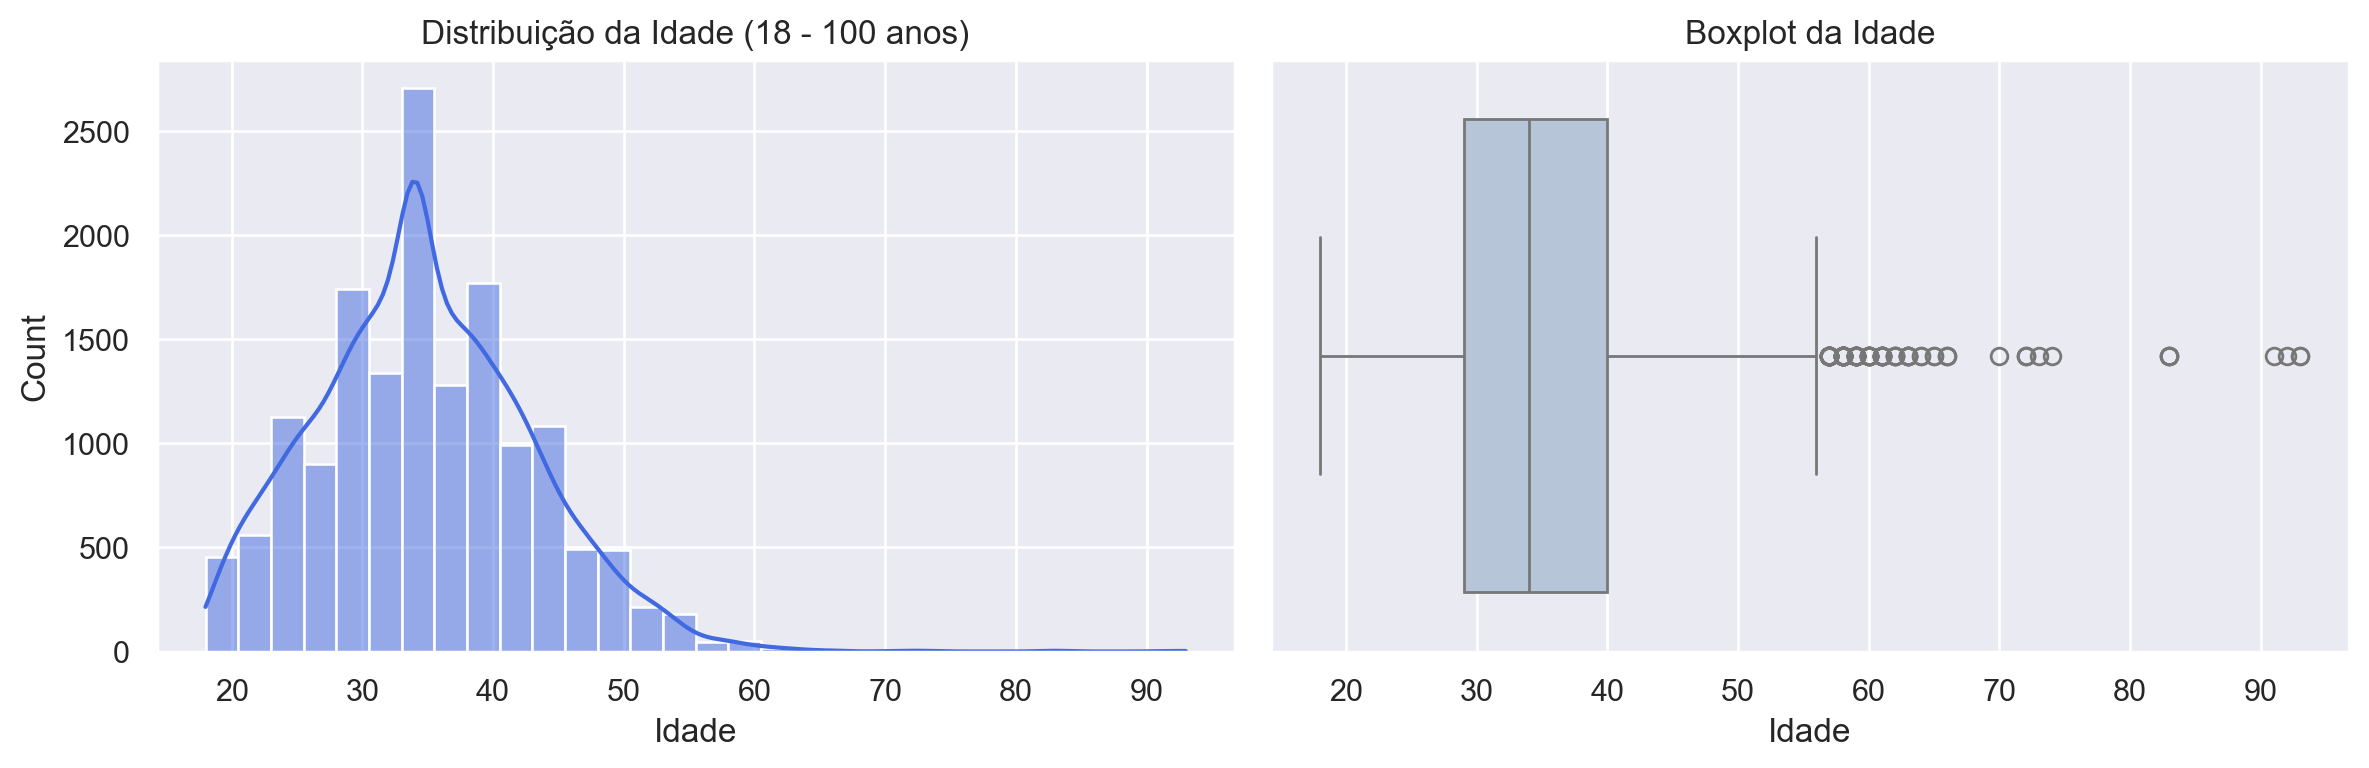

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histograma com KDE
sns.histplot(df['age'], bins=30, kde=True, ax=axes[0], color='royalblue')
axes[0].set_title('Distribuição da Idade (18 - 100 anos)')
axes[0].set_xlabel('Idade')

# Boxplot para deteção de outliers estatísticos
sns.boxplot(x=df['age'], ax=axes[1], color='lightsteelblue')
axes[1].set_title('Boxplot da Idade')
axes[1].set_xlabel('Idade')

plt.tight_layout()
plt.show()

## GENDER:
- Object
- Já demos replace a "" por NaN e tem 530 missing values.

In [40]:
df["gender"].unique()

array(['Female', 'Male', 'F', 'Other', nan, ' Female', 'M', 'male',
       ' Male', 'other', ' Other', 'female', 'O'], dtype=object)

In [41]:
print(df['gender'].value_counts(dropna=False))

gender
Female     7405
Male       6166
NaN         530
Other       465
female      169
F           143
 Female     141
M           138
male        132
 Male       129
other        15
 Other        9
O             8
Name: count, dtype: int64


In [42]:
# Dicionário de mapeamento: se encontrar o que está no lado esquerdo, tranforma no lado direito
mapa_genero = {
    'female': 'Female',
    'f': 'Female',
    'male': 'Male',
    'm': 'Male',
    'other': 'Other',
    'o': 'Other'
}

# Limpar espaços, colocar em minúsculas e mapear
df['gender'] = (
    df['gender']
    .astype(str)
    .str.strip()
    .str.lower()
    .map(mapa_genero)  # Transforma 'nan' e valores não mapeados de volta em NaN
)

# Confirmar os valores únicos limpos
print("Valores únicos após padronização:")
print(df['gender'].unique())

print("\nFrequência absoluta após limpeza:")
print(df['gender'].value_counts(dropna=False))

Valores únicos após padronização:
['Female' 'Male' 'Other' nan]

Frequência absoluta após limpeza:
gender
Female    7858
Male      6565
NaN        530
Other      497
Name: count, dtype: int64


In [47]:
#defini os missing values como Unknown
df['gender'] = df['gender'].fillna('Unknown')
#definir a variavél como categorica
df['gender'] = df['gender'].astype('category')
print("\nCategorias:")
print(df['gender'].cat.categories.tolist())

print("\nDistribuição final dos membros por género:")
print(df['gender'].value_counts())


Categorias:
['Female', 'Male', 'Other', 'Unknown']

Distribuição final dos membros por género:
gender
Female     7858
Male       6565
Unknown     530
Other       497
Name: count, dtype: int64


## INDUSTRY:
- Object
- 0 missing values

In [48]:
df["industry"].unique()

array(['Information Technology', 'Education', 'Legal', 'Health',
       'Unknown', 'Other', 'Consulting', 'Design & Creative',
       'information technology', 'Finance', 'Marketing & PR', 'EDUCATION',
       'DESIGN & CREATIVE', 'Marketing and PR', 'Real Estate', 'other',
       'consulting', 'MARKETING & PR', 'Information technology',
       'design & creative', 'LEGAL', 'marketing & pr',
       'INFORMATION TECHNOLOGY', 'health', 'Marketing/PR', 'CONSULTING',
       'unknown', 'Design/Creative', 'RealEstate', 'IT', 'Tech',
       'Marketing & Pr', 'OTHER', 'legal', 'finance', 'real estate',
       'education', 'Design and Creative', 'UNKNOWN', 'FINANCE',
       'REAL ESTATE', 'HEALTH', 'Real-Estate'], dtype=object)

In [49]:
mapa_industria = {
    # Information Technology
    'information technology': 'Information Technology',
    'it': 'Information Technology',
    'tech': 'Information Technology',
    
    # Consulting
    'consulting': 'Consulting',
    
    # Marketing & PR
    'marketing & pr': 'Marketing & PR',
    'marketing and pr': 'Marketing & PR',
    'marketing/pr': 'Marketing & PR',
    
    # Design & Creative
    'design & creative': 'Design & Creative',
    'design and creative': 'Design & Creative',
    'design/creative': 'Design & Creative',
    
    # Finance
    'finance': 'Finance',
    
    # Legal
    'legal': 'Legal',
    
    # Education
    'education': 'Education',
    
    # Health
    'health': 'Health',
    
    # Real Estate
    'real estate': 'Real Estate',
    'realestate': 'Real Estate',
    'real-estate': 'Real Estate',
    
    # Outros e Desconhecidos
    'other': 'Other',
    'unknown': 'Unknown'
}

df['industry'] = (
    df['industry']
    .astype(str)
    .str.strip()
    .str.lower()
    .map(mapa_industria)
)

# Converter para variável categórica
df['industry'] = df['industry'].astype('category')

print("Valores únicos consolidados:")
print(df['industry'].cat.categories.tolist())

print("\nDistribuição por indústria (frequência absoluta e percentagem):")
distribuicao = pd.DataFrame({
    'Contagem': df['industry'].value_counts(),
    'Percentagem (%)': (df['industry'].value_counts(normalize=True) * 100).round(2)
})
print(distribuicao)

Valores únicos consolidados:
['Consulting', 'Design & Creative', 'Education', 'Finance', 'Health', 'Information Technology', 'Legal', 'Marketing & PR', 'Other', 'Real Estate', 'Unknown']

Distribuição por indústria (frequência absoluta e percentagem):
                        Contagem  Percentagem (%)
industry                                         
Information Technology      3557            23.02
Consulting                  2055            13.30
Design & Creative           1974            12.78
Marketing & PR              1962            12.70
Finance                     1219             7.89
Other                       1175             7.61
Legal                        878             5.68
Education                    775             5.02
Unknown                      693             4.49
Health                       601             3.89
Real Estate                  561             3.63


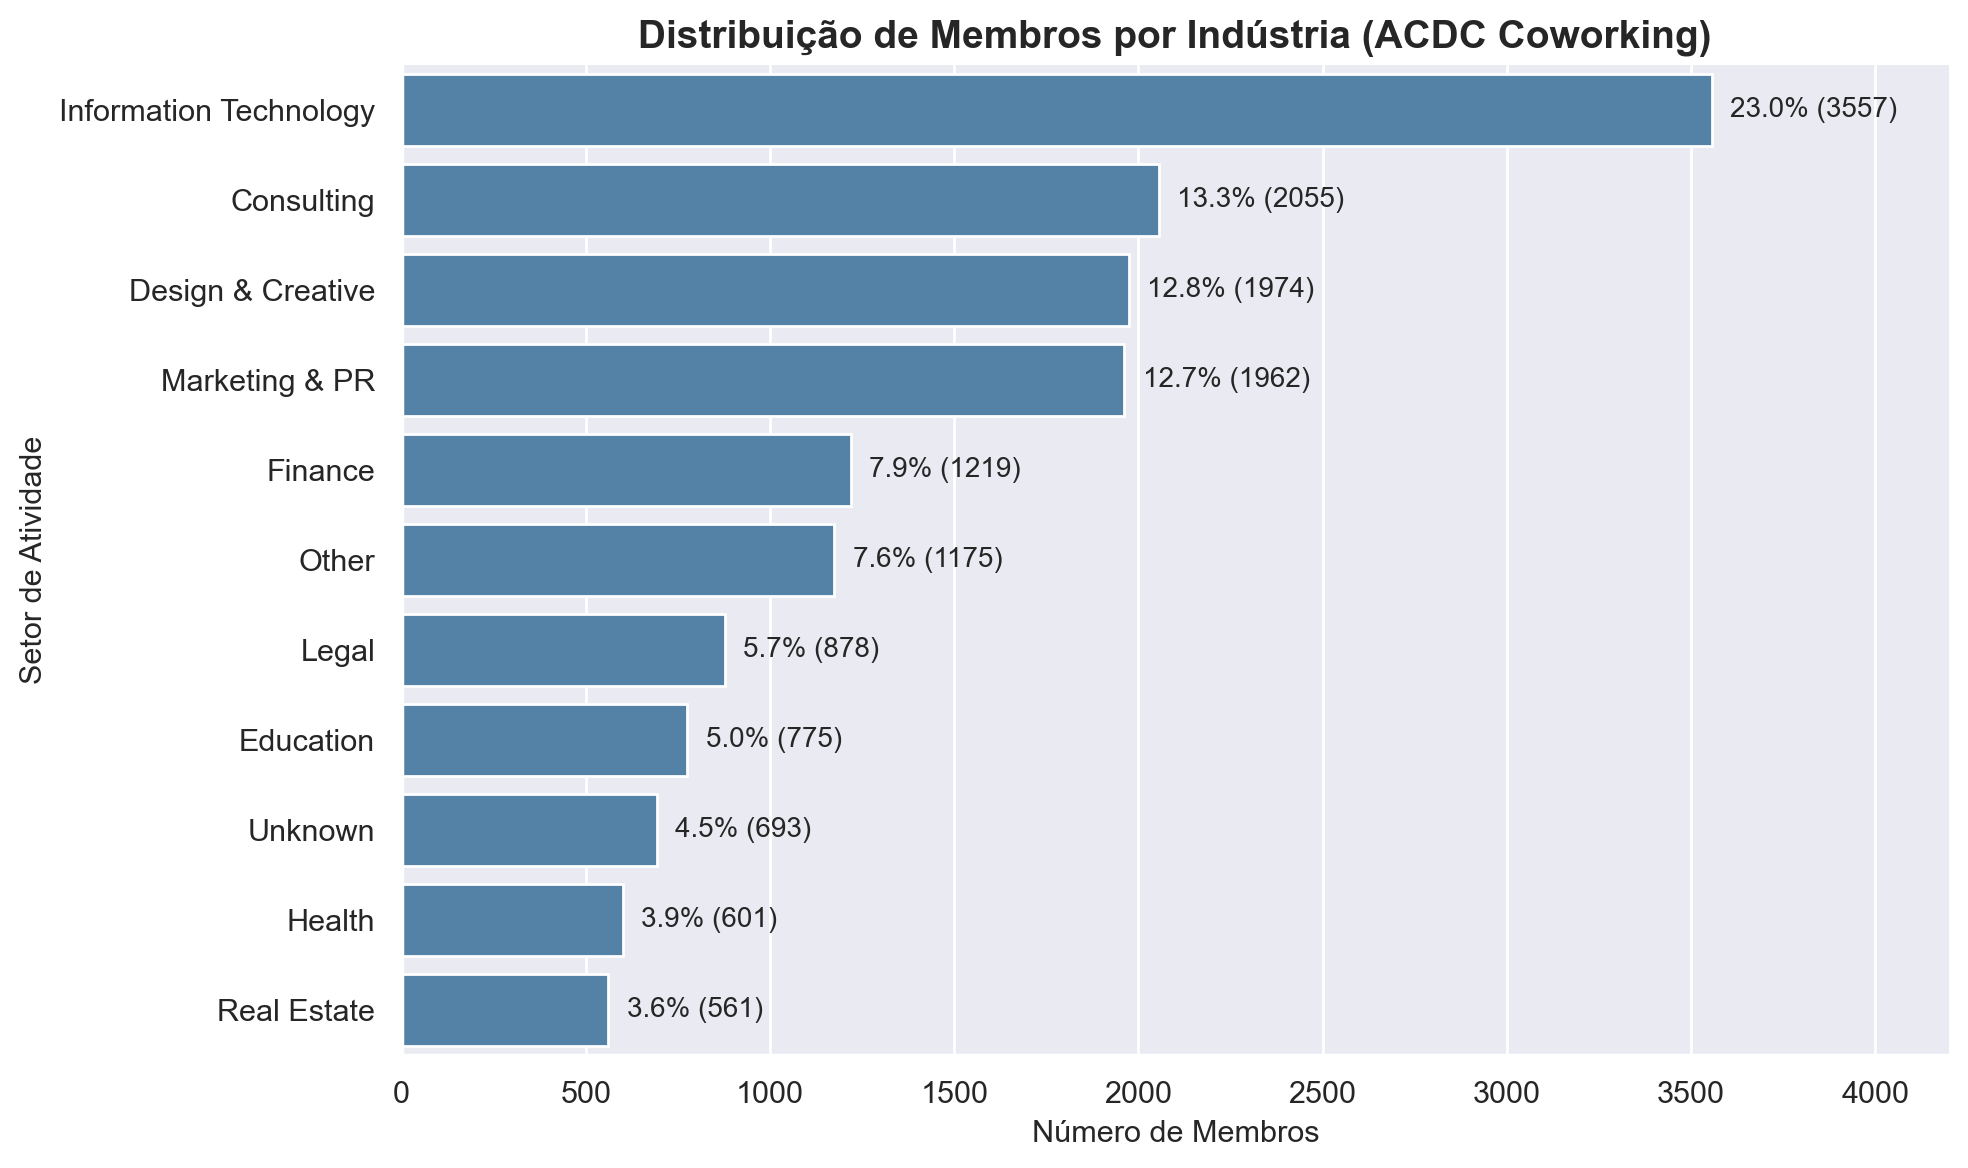

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

ordem = df['industry'].value_counts().index
total = len(df)

plt.figure(figsize=(10, 6))
ax = sns.countplot(
    data=df, 
    y='industry', 
    order=ordem, 
    color='steelblue'    
)

# Adicionar os rótulos de percentagem e contagem
for p in ax.patches:
    largura = p.get_width()
    if largura > 0:
        pct = (largura / total) * 100
        ax.annotate(f'{pct:.1f}% ({int(largura)})',
                    (largura + 50, p.get_y() + p.get_height() / 2),
                    va='center', fontsize=10)

plt.title('Distribuição de Membros por Indústria (ACDC Coworking)', fontsize=14, fontweight='bold')
plt.xlabel('Número de Membros', fontsize=11)
plt.ylabel('Setor de Atividade', fontsize=11)
plt.xlim(0, 4200)
sns.despine()
plt.tight_layout()
plt.show()